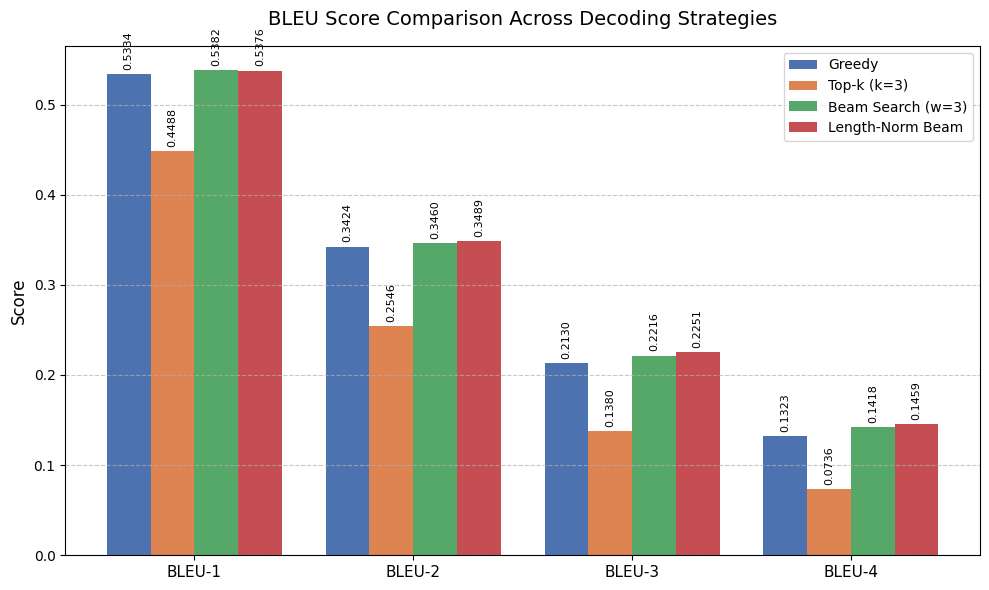

Chart successfully generated and saved as bleu_comparison_chart.png


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import os

# The exact BLEU scores from your evaluation
metrics = ['BLEU-1', 'BLEU-2', 'BLEU-3', 'BLEU-4']
greedy_scores = [0.5334, 0.3424, 0.2130, 0.1323]
top_k_scores = [0.4488, 0.2546, 0.1380, 0.0736]
beam_search_scores = [0.5382, 0.3460, 0.2216, 0.1418]
length_norm_scores = [0.5376, 0.3489, 0.2251, 0.1459]

x = np.arange(len(metrics))  # Label locations
width = 0.2  # Width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting each strategy
rects1 = ax.bar(x - 1.5*width, greedy_scores, width, label='Greedy', color='#4C72B0')
rects2 = ax.bar(x - 0.5*width, top_k_scores, width, label='Top-k (k=3)', color='#DD8452')
rects3 = ax.bar(x + 0.5*width, beam_search_scores, width, label='Beam Search (w=3)', color='#55A868')
rects4 = ax.bar(x + 1.5*width, length_norm_scores, width, label='Length-Norm Beam', color='#C44E52')

# Text formatting and labels
ax.set_ylabel('Score', fontsize=12)
ax.set_title('BLEU Score Comparison Across Decoding Strategies', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add exact score values on top of the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, rotation=90)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

fig.tight_layout()

# Display the plot in the notebook
plt.show()

# Save the plot to the current working directory
fig.savefig('bleu_comparison_chart.png', dpi=300)
print("Chart successfully generated and saved as bleu_comparison_chart.png")

In [2]:
import sys
import os

# Add the src directory to Python's path so we can import your functions
PROJECT_ROOT = os.path.dirname(os.getcwd())
sys.path.append(os.path.join(PROJECT_ROOT, 'src'))

from evaluate_bleu import load_artifacts, generate_caption, beam_search_caption

# Load the trained model and features
model, tokenizer, feature_dict = load_artifacts()

# The exact images Kevan is using for his error analysis
test_images = [
    '987907964_5a06a63609.jpg', 
    '3524612244_64f00afec5.jpg', 
    '429283612_37f6e7fb7f.jpg'
]

max_len = 39

for img_id in test_images:
    # Ensure the image ID matches the format in your feature_dict
    clean_id = img_id.split('.')[0] if img_id not in feature_dict else img_id
    
    if clean_id not in feature_dict:
        print(f"Feature not found for {img_id}")
        continue
        
    print(f"\n--- Generating Captions for {img_id} ---")
    feature = feature_dict[clean_id]
    
    # Run all four strategies
    greedy = generate_caption(model, tokenizer, feature, max_len, strategy='greedy')
    top_k = generate_caption(model, tokenizer, feature, max_len, strategy='top_k')
    beam = beam_search_caption(model, tokenizer, feature, max_len, strategy='beam_search')
    length_norm = beam_search_caption(model, tokenizer, feature, max_len, strategy='length_norm')
    
    print(f"Greedy Baseline:     {greedy}")
    print(f"Standard Beam (w=3): {beam}")
    print(f"Top-k (k=3):         {top_k}")
    print(f"Length-Norm Beam:    {length_norm}")

Loading model and features...

--- Generating Captions for 987907964_5a06a63609.jpg ---
Greedy Baseline:     a dog is running through a field
Standard Beam (w=3): a black and white dog is running in the grass
Top-k (k=3):         two dogs play in the grass
Length-Norm Beam:    a black and white dog is running in the grass

--- Generating Captions for 3524612244_64f00afec5.jpg ---
Greedy Baseline:     a man in a black shirt is standing in front of a crowd
Standard Beam (w=3): a group of people are standing in front of a crowd
Top-k (k=3):         the girl wearing the black jacket is sitting in the street with a man in the background
Length-Norm Beam:    a group of people are standing in front of a crowd

--- Generating Captions for 429283612_37f6e7fb7f.jpg ---
Greedy Baseline:     a man in a red shirt is riding a skateboard on a skateboard
Standard Beam (w=3): a man in a red shirt is riding a bike
Top-k (k=3):         a boy is riding a skateboard in the air
Length-Norm Beam:    a man in